# Enunciado
Se trata de un tubo en U, con longitud L de menisco a menisco, en donde los meniscos se desplazan a partir de un movimiento inicial.
![[Pasted image 20260415121901.png|194]]
Teniendo las siguientes condiciones iniciales.
$z(0)=0.25\ m$
$v(0)=0\ m/s$
$L=1.225\ m$
Se tienen las siguientes EDOs, que describen el movimiento,

$$\begin{align}
\frac{dv}{dt} &=-\frac{2g}{L}\cdot z \tag{1} \\
\frac{dz}{dt} &=v \tag{2}
\end{align}$$
Reemplazando la velocidad de (2) en (1), se tiene, para la parte izquierda de la ecuacion.
$$
\frac{d^2z}{dt^2}=-\frac{2g}{L} \cdot z \tag{3}
$$
1. Calcular la evolucion temporal de la velocidad $v$ y la posicion $z$, usando el sistema de EDOs. Para esto construir el codigo usando multipaso de tercer orden.
2. Cual es la maxima velocidad
3. Cual es el maximo valor de z
4. Cual es el periodo de oscilacion
5. Obtenga la solucion analitica
6. Compara la solucion analitica con la solucion numerica para z
# Solucion numerica Python
El codigo requiere que se utilice un [[Metodo de Multipaso]] de tercer orden.
## Diagrama de flujo
## Explicacion del codigo
Llamamos las librerias, las cuales se usaran para dibujar, y para usar las funciones matematicas que no estan presentes en python por defecto, como por ejemplo la raiz cuadrada.
```
import matplotlib.pyplot as plt
import numpy as np
```
Luego, colocamos todas las constantes de corrido, para ahorrar espacio, el cual se llama desempaquetado de tuplas.
```
g, L, z0, v0, h, tf = 9.8,1.225, 0.25, 0.0, 0.01, 5.
```
Aqui se calculara la velocidad angular, la cual se obtuvo de la EDO (3), es decir.
$$
\frac{d^2z}{dt^2}=-\frac{2g}{L} \cdot z=-\left(\sqrt{\frac{2g}{L}}\right)^2 \cdot z=\omega^2 \cdot z
$$
```
w = np.sqrt(2 * g / L)
```
## Codigo

z_max: 0.2500
v_max: 0.9999
Periodo: 1.5700


<string>:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


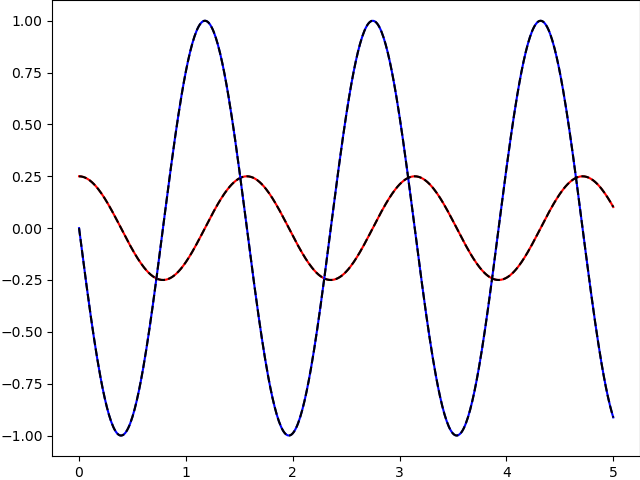

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Datos del problema y arreglos
g, L, z0, v0, h, tf = 9.8,1.225, 0.25, 0.0, 0.01, 5.0
w = np.sqrt(2 * g / L)
t = np.arange(0, tf + h, h)
N = len(t)

z, v = np.zeros(N), np.zeros(N)
z[0], v[0] = z0, v0

def f(z_val, v_val):
    return v_val, -(2 * g / L) * z_val

# 2. Arranque (RK4 para obtener los pasos 1 y 2)
for i in range(2):
    k1z, k1v = f(z[i], v[i])
    k2z, k2v = f(z[i] + h / 2 * k1z, v[i] + h / 2 * k1v)
    k3z, k3v = f(z[i] + h / 2 * k2z, v[i] + h / 2 * k2v)
    k4z, k4v = f(z[i] + h * k3z, v[i] + h * k3v)
    z[i + 1] = z[i] + h / 6 * (k1z + 2 * k2z + 2 * k3z + k4z)
    v[i + 1] = v[i] + h / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)

# 3. Algoritmo Principal (Multipaso AB3)
for i in range(2, N - 1):
    f0z, f0v = f(z[i], v[i])
    f1z, f1v = f(z[i - 1], v[i - 1])
    f2z, f2v = f(z[i - 2], v[i - 2])
    z[i + 1] = z[i] + h / 12 * (23 * f0z - 16 * f1z + 5 * f2z)
    v[i + 1] = v[i] + h / 12 * (23 * f0v - 16 * f1v + 5 * f2v)

# 4. Extracción de Resultados (Preguntas 2 y 3)
z_max, v_max = max(z), max(abs(v))
T = 0
for i in range(1, N - 1):
    if z[i] > z[i - 1] and z[i] > z[i + 1]:  # Detecta el primer pico
        T = t[i]
        break

print(f"z_max: {z_max:.4f}\nv_max: {v_max:.4f}\nPeriodo: {T:.4f}")

# 5. Gráficos rápidos (Línea continua = Numérica, Línea discontinua = Analítica)
plt.plot(t, z, "r", t, z0 * np.cos(w * t), "k--")
plt.show()
plt.plot(t, v, "b", t, -z0 * w * np.sin(w * t), "k--")
plt.show()

# Solucion numerica Matlab
## Explicacion del codigo
### 1.Introduccion de datos
Aqui se meten datos, todos.
```
g = 9.8; L = 1.225; z0 = 0.25; v0 = 0; h = 0.01; tf = 5;
```
Luego se coloca la ecuacion para la velocidad angular
Seguido de una variable de tiempo $t$, la cual ira desde 0 a tf, en este caso se dio un paso de tiempo $h=0.01$, y un tiempo final $t_f=5\ s$.
Luego se creara un numero N, el cual alamacenara el numero de elementos de la lista t, es decir $\frac{(5-0)}{0.01}+1=501$ elementos.
```
w = sqrt(2 * g / L); t = 0:h:tf; N = length(t);
```
Luego, para z y v, se crearan dos matrices con 1 fila y N numero de columnas, en este caso 501 columnas, esto para almacenar mas adelante los valores que nos daran los bucles.
```
z = zeros(1, N); v = zeros(1, N);
```

Ahora se colocaran las condiciones iniciales, para el [[Metodo de Multipaso]], esto seria el paso 1. Se coloca en funcion de 1, por que es desde 1 que matlab contara las iteraciones, y las colocara en la primer celda de la matriz z y v, es decir
![[Pasted image 20260602150858.png|295]]
```
z(1) = z0; v(1) = v0;
```

Se crearan funciones anonimas las cuales siguen la forma tal que 
```
funcion=@(variable1,variable2,varible3) operacion_con_la_variable
```
A pesar de que en las dos funciones no se usan todas las variables, es valido ponerlas igual, para que se entienda mejor.
```
fz = @(z, v) v;
fv = @(z, v) -(w^2) * z;
```
### RK4
Para usar el metodo de Adams-Bashforth se necesitan pasos previos, 3 para ser precisos. el primero ya lo tenemos, las condiciones iniciales, y los otros 2 los calcularemos con el [[Metodo Runge - Kutta]] de cuarto orden

Para los indices 1 y 2, donde en 1 se tienen las condiciones iniciales para calcular el indice 2 se usa el bucle for por primera vez y para obtener el tercer indice, sera el resultado final a la salida del bucle.

Se conoce la forma normal del metodo de RK4, pero esta vez son dos ecuaciones, por un lado la velocidad depende del espacio, pero a su vez el espacio depende de la velocidad. Por lo que se aplicara RK4 en ambas al mismo tiempo, de forma acoplada. 
```
for i = 1:2
    k1z = fz(z(i), v(i)); k1v = fv(z(i), v(i));
    k2z = fz(z(i)+h/2*k1z, v(i)+h/2*k1v); k2v = fv(z(i)+h/2*k1z, v(i)+h/2*k1v);
    k3z = fz(z(i)+h/2*k2z, v(i)+h/2*k2v); k3v = fv(z(i)+h/2*k2z, v(i)+h/2*k2v);
    k4z = fz(z(i)+h*k3z, v(i)+h*k3v);     k4v = fv(z(i)+h*k3z, v(i)+h*k3v);
    z(i+1) = z(i) + h/6 * (k1z + 2*k2z + 2*k3z + k4z);
    v(i+1) = v(i) + h/6 * (k1v + 2*k2v + 2*k3v + k4v);
end
```
### AB3

## Codigo
```
clc, clear
% 1. Datos del problema y arreglos
g = 9.8; L = 1.225; z0 = 0.25; v0 = 0; h = 0.01; tf = 5;
w = sqrt(2 * g / L); t = 0:h:tf; N = length(t);
z = zeros(1, N); v = zeros(1, N);
z(1) = z0; v(1) = v0;

fz = @(z, v) v;
fv = @(z, v) -(w^2) * z;

% 2. Arranque (RK4 para obtener pasos 2 y 3)
for i = 1:2
    k1z = fz(z(i), v(i));          k1v = fv(z(i), v(i));
    k2z = fz(z(i)+h/2*k1z, v(i)+h/2*k1v); k2v = fv(z(i)+h/2*k1z, v(i)+h/2*k1v);
    k3z = fz(z(i)+h/2*k2z, v(i)+h/2*k2v); k3v = fv(z(i)+h/2*k2z, v(i)+h/2*k2v);
    k4z = fz(z(i)+h*k3z, v(i)+h*k3v);     k4v = fv(z(i)+h*k3z, v(i)+h*k3v);
    z(i+1) = z(i) + h/6 * (k1z + 2*k2z + 2*k3z + k4z);
    v(i+1) = v(i) + h/6 * (k1v + 2*k2v + 2*k3v + k4v);
end

% 3. Algoritmo Principal (Multipaso AB3)
for i = 3:N-1
    f0z = fz(z(i), v(i));         f0v = fv(z(i), v(i));
    f1z = fz(z(i-1), v(i-1));     f1v = fv(z(i-1), v(i-1));
    f2z = fz(z(i-2), v(i-2));     f2v = fv(z(i-2), v(i-2));
    z(i+1) = z(i) + h/12 * (23*f0z - 16*f1z + 5*f2z);
    v(i+1) = v(i) + h/12 * (23*f0v - 16*f1v + 5*f2v);
end

% 4. Extracción de Resultados (Preguntas 2 y 3)
z_max = max(z); v_max = max(abs(v)); T = 0;
for i = 2:N-1
    if z(i) > z(i-1) && z(i) > z(i+1), T = t(i); break; end
end
fprintf('z_max: %.4f\nv_max: %.4f\nPeriodo: %.4f\n', z_max, v_max, T);

% 5. Gráficos rápidos (Abre dos ventanas independientes)
figure; plot(t, z, 'r', t, z0*cos(w*t), 'k--');
figure; plot(t, v, 'b', t, -z0*w*sin(w*t), 'k--');
```
# Solucion analitica
Se deben de partir de las ecuaciones dadas en el problema xd.
Empezamos por utilizar la ecuacion (22) de [[Tubo en U sin friccion]], se tiene.
$$
z(t) = Z_0\cos\left(\sqrt{\frac{2g}{L}}\,t\right)\tag{1}
$$
Nos dicen que $z(0)=0.25$, es decir que en el primer instante de tiempo, se tiene una diferencia de altura para un menisco de $0.25\ m$.
Tambien nos dan ua longitud del menisco de $L=1.225\ m$. Reemplazando en la ecuacion se tiene.
$$
z(t) = 0.25\cos\left(\sqrt{\frac{2g}{1.225}}\,t\right)
$$
## Maximo valor de Z
Como $\cos(\ )=[-1;1]$, entonces el maximo valor que puede tomar seria 1, entonces en cualquier instante de tiempo $t$, se tiene un valor maximo de la altura de $0.25\ m$.
$$
z(t) = 0.25\ [m]
$$
## Velocidad angular
Por [[Movimiento Armonico Simple]] se sabe que el termino de la velocidad angular $\omega$ es igual a.
$$
\omega=\sqrt{\frac{2g}{L}}=\sqrt{\frac{2g}{1.225}}
$$
$$
\omega=4\ [\frac{rad}{s}]
$$
Entonces la ecuacion (1) quedaria como
$$
z(t) = 0.25\cos(4t)\tag{2}
$$
## Maxima velocidad
Si notamos la ecuacion (1), tambien notamos que se trata de la posicion, y si derivamos la posicion obtendremos la velocidad, es decir
$$
\frac{dz}{dt}=v(t)=\frac{d}{dt}(\cos(4t)
$$
$$
v(t)=0.25(-4\,\sin(4t))
$$
Como $\sin(\ )=[-1;1]$, y la velocidad debe ser positiva, seleccionaremos el valor de -1, obteniendo.
$$
v(t)_{max}=1\ [\frac{m}{s}]
$$
## Periodo
El periodo segun [[Movimiento Armonico Simple]] se define como.
$$
T=\frac{2\pi}{\omega}
$$
Sabiendo que $\omega=4$, se tiene.
$$
T=1.57\ [s]
$$